<a href="https://colab.research.google.com/github/yilunge6-cyber/p6-ieee33-loadflow/blob/main/notebooks/p6_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandapower
import copy, os
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn
import pandapower.shortcircuit as sc
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("pandapower", pp.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 30.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 69.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.6/604.6 kB 21.4 MB/s  0:00:00
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [pandapower]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
pandapower 3.5.6


In [2]:
net = pn.case33bw()
print(net)

This pandapower network includes the following parameter tables:
   - bus (33 elements)
   - load (32 elements)
   - ext_grid (1 element)
   - line (37 elements)
   - poly_cost (1 element)


In [3]:
net.bus.head(10)        # first 10 rows of the bus table

,name,vn_kv,type,zone,in_service,max_vm_pu,min_vm_pu,geo
0,0,12.66,b,1.0,True,1.0,1.0,"{""coordinates"": [-1.0272036165, 0.2320163609],..."
1,1,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [-1.7116237332, 1.1564808132],..."
2,2,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [-2.9808633284, 0.7559599298],..."
3,3,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [-3.522358388, 1.8171551243], ..."
4,4,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [-2.731321429, 2.6315460884], ..."
5,5,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [-1.5607015286, 2.2856553455],..."
6,6,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [-0.4497150199, 2.8656670376],..."
7,7,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [0.941973628, 2.8780598262], ""..."
8,8,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [2.1728023414, 2.7324381671], ..."
9,9,12.66,b,1.0,True,1.1,0.9,"{""coordinates"": [2.6767808518, 3.8288255046], ..."


In [4]:
net.line.head(10)

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,max_loading_percent,geo
0,None,None,0,1,1.0,0.0922,0.0470,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
1,None,None,1,2,1.0,0.4930,0.2511,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
2,None,None,2,3,1.0,0.3660,0.1864,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
3,None,None,3,4,1.0,0.3811,0.1941,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
4,None,None,4,5,1.0,0.8190,0.7070,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
5,None,None,5,6,1.0,0.1872,0.6188,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
6,None,None,6,7,1.0,0.7114,0.2351,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
7,None,None,7,8,1.0,1.0300,0.7400,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
8,None,None,8,9,1.0,1.0440,0.7400,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None
9,None,None,9,10,1.0,0.1966,0.0650,0.0,0.0,99999.0,1.0,1,ol,True,100.0,None


In [5]:
net.load.head(10)

,name,bus,p_mw,q_mvar,const_z_p_percent,const_z_q_percent,const_i_p_percent,const_i_q_percent,sn_mva,scaling,in_service,type,controllable
0,None,1,0.100,0.06,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
1,None,2,0.090,0.04,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
2,None,3,0.120,0.08,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
3,None,4,0.060,0.03,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
4,None,5,0.060,0.02,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
5,None,6,0.200,0.10,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
6,None,7,0.200,0.10,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
7,None,8,0.060,0.02,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
8,None,9,0.060,0.02,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
9,None,10,0.045,0.03,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False


In [6]:
net.ext_grid

,name,bus,vm_pu,va_degree,slack_weight,in_service,max_p_mw,min_p_mw,max_q_mvar,min_q_mvar
0,None,0,1.0,0.0,1.0,True,10.0,0.0,10.0,-10.0


In [7]:
n_bus   = len(net.bus)
n_lines = int(net.line.in_service.sum())
n_ties  = int((~net.line.in_service).sum())
p_load  = net.load.p_mw.sum()
q_load  = net.load.q_mvar.sum()
print(f"{n_bus} buses, {n_lines} lines in service, {n_ties} ties")
print(f"Load: {p_load:.3f} MW, {q_load:.3f} Mvar")

33 buses, 32 lines in service, 5 ties
Load: 3.715 MW, 2.300 Mvar


In [8]:
pp.runpp(net)
print(net.res_bus.head(20))

       vm_pu  va_degree      p_mw    q_mvar
0   1.000000   0.000000 -3.917677 -2.435141
1   0.997032   0.014481  0.100000  0.060000
2   0.982938   0.096042  0.090000  0.040000
3   0.975456   0.161651  0.120000  0.080000
4   0.968059   0.228285  0.060000  0.030000
5   0.949658   0.133853  0.060000  0.020000
6   0.946173  -0.096474  0.200000  0.100000
7   0.941328  -0.060403  0.200000  0.100000
8   0.935059  -0.133485  0.060000  0.020000
9   0.929244  -0.196014  0.060000  0.020000
10  0.928384  -0.188761  0.045000  0.030000
11  0.926885  -0.177269  0.060000  0.035000
12  0.920772  -0.268587  0.060000  0.035000
13  0.918505  -0.347268  0.120000  0.080000
14  0.917093  -0.384950  0.060000  0.010000
15  0.915725  -0.408205  0.060000  0.020000
16  0.913698  -0.485473  0.060000  0.020000
17  0.913090  -0.495063  0.090000  0.040000
18  0.996504   0.003651  0.090000  0.040000
19  0.992926  -0.063328  0.090000  0.040000


In [9]:
v       = net.res_bus.vm_pu
vmin    = v.min()
imin    = v.idxmin()
loss_kw = net.res_line.pl_mw.sum() * 1000
supply  = net.res_ext_grid.p_mw.sum()

print(f"Minimum voltage: {vmin:.4f} pu at IEEE bus {imin + 1}")
print(f"Total losses:    {loss_kw:.1f} kW")
print(f"Substation supplies {supply:.3f} MW for {p_load:.3f} MW of load")

low = [i + 1 for i in v.index if v[i] < 0.95]
print(f"{len(low)} buses below 0.95 pu (IEEE numbers): {low}")

Minimum voltage: 0.9131 pu at IEEE bus 18
Total losses:    202.7 kW
Substation supplies 3.918 MW for 3.715 MW of load
21 buses below 0.95 pu (IEEE numbers): [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 26, 27, 28, 29, 30, 31, 32, 33]


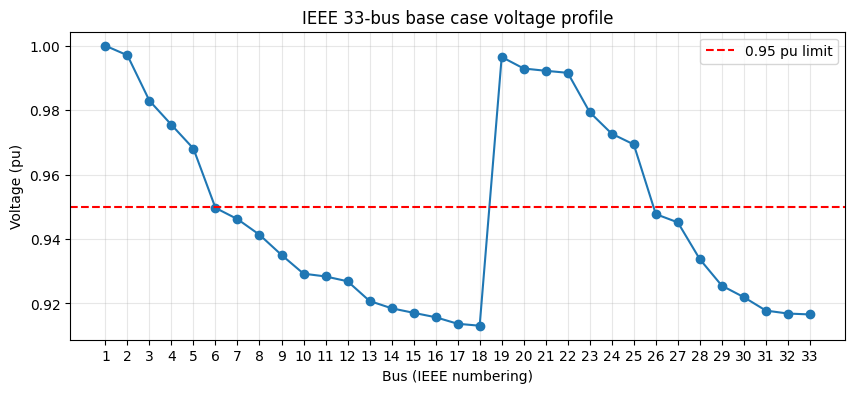

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(v.index + 1, v.values, marker="o")
ax.axhline(0.95, linestyle="--", color="red", label="0.95 pu limit")
ax.set_xlabel("Bus (IEEE numbering)")
ax.set_ylabel("Voltage (pu)")
ax.set_title("IEEE 33-bus base case voltage profile")
ax.set_xticks(range(1, 34))
ax.grid(alpha=0.3)
ax.legend()
fig.savefig("figures/voltage_base.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
def run_scenario(base_net, scale):
    """Run a load flow with every load multiplied by `scale`.
    Returns a summary dict and the voltage at every bus."""
    n = copy.deepcopy(base_net)          # 1. work on a copy
    n.load["scaling"] = scale            # 2. scale every load
    pp.runpp(n)                          # 3. solve
    v = n.res_bus.vm_pu                  # 4. read results
    summary = {
        "load_scale": scale,
        "vmin_pu": round(v.min(), 4),
        "vmin_bus_ieee": int(v.idxmin()) + 1,
        "losses_kw": round(n.res_line.pl_mw.sum() * 1000, 1),
        "buses_below_095": int((v < 0.95).sum()),
    }
    return summary, v

In [13]:
net = pn.case33bw()                  # clean base network
rows, profiles = [], {}
for name, s in [("Light", 0.5), ("Nominal", 1.0), ("Peak", 1.3)]:
    summary, v = run_scenario(net, s)
    rows.append({"scenario": name, **summary})
    profiles[name] = v

table2 = pd.DataFrame(rows)
table2.to_csv("results/table2_scenarios.csv", index=False)
table2

,scenario,load_scale,vmin_pu,vmin_bus_ieee,losses_kw,buses_below_095
0,Light,0.5,0.9583,18,47.1,0
1,Nominal,1.0,0.9131,18,202.7,21
2,Peak,1.3,0.8839,18,359.8,21


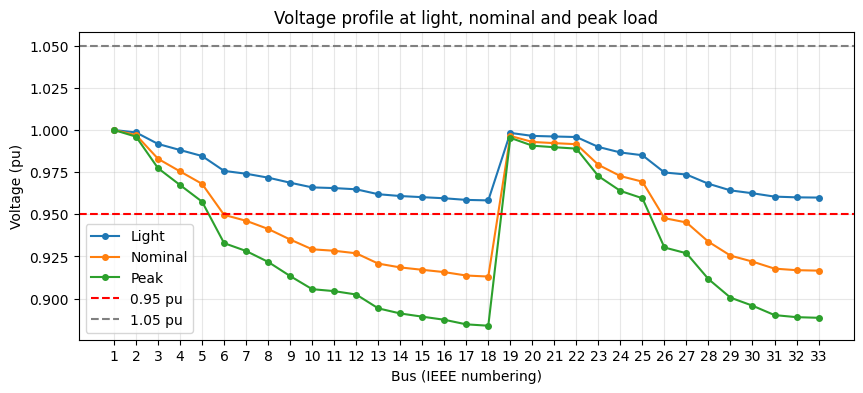

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, v in profiles.items():
    ax.plot(v.index + 1, v.values, marker="o", markersize=4, label=name)
ax.axhline(0.95, linestyle="--", color="red", label="0.95 pu")
ax.axhline(1.05, linestyle="--", color="gray", label="1.05 pu")
ax.set_xlabel("Bus (IEEE numbering)"); ax.set_ylabel("Voltage (pu)")
ax.set_title("Voltage profile at light, nominal and peak load")
ax.set_xticks(range(1, 34)); ax.grid(alpha=0.3); ax.legend()
fig.savefig("figures/voltage_scenarios.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
L = table2.set_index("scenario")["losses_kw"]
print("Peak / nominal  :", round(L["Peak"] / L["Nominal"], 3), " (simple theory: 1.69)")
print("Light / nominal :", round(L["Light"] / L["Nominal"], 3), " (simple theory: 0.25)")

Peak / nominal  : 1.775  (simple theory: 1.69)
Light / nominal : 0.232  (simple theory: 0.25)
